# Handling Imbalanced Data

In many important problems, the interesting class is rare: fraud, disease, churn, a client who says yes. With 11 % positives, a model that always says "no" is 89 % accurate and completely useless. Imbalance mostly changes **how you evaluate and decide**, not only how you train.

**After this lesson you can:**

1. Choose metrics for imbalanced problems: precision, recall, PR AUC, cost.
2. Use class weights, resampling (random over/under-sampling, SMOTE) correctly inside pipelines.
3. Tune the decision threshold for a business cost.
4. Explain why resampling changes probabilities, and how to correct for it.

**Data:** Bank Marketing (11.3 % subscriptions), without the leaky `duration` (Lesson 09).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix, precision_recall_curve,
                             roc_auc_score)
from sklearn.model_selection import TunedThresholdClassifierCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

bank = datasets.bank_marketing().drop(columns="duration")
y = (bank.pop("y") == "yes").astype(int)
cat = bank.select_dtypes(include="str").columns.tolist()
num = bank.columns.difference(cat).tolist()
pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
X_tr, X_te, y_tr, y_te = train_test_split(bank, y, test_size=0.25, stratify=y, random_state=RNG)
print(f"positives: train {y_tr.mean():.3f}, test {y_te.mean():.3f}")

positives: train 0.113, test 0.113


## 1. The Accuracy Trap and Better Metrics

| Metric | Question |
| :--- | :--- |
| precision | of the clients we call, how many subscribe? |
| recall | of all clients who would subscribe, how many do we call? |
| ROC AUC | how well are positives ranked above negatives? (insensitive to imbalance) |
| **PR AUC** (average precision) | precision across all recall levels; baseline = positive rate |

In [2]:
always_no = np.zeros_like(y_te)
base = make_pipeline(pre, LogisticRegression(max_iter=3000)).fit(X_tr, y_tr)
p = base.predict_proba(X_te)[:, 1]
print(f"'always no' accuracy: {(always_no == y_te).mean():.3f} | recall: 0.000")
print(f"logistic regression accuracy at threshold 0.5: {((p > 0.5) == y_te).mean():.3f}")
print(f"ROC AUC {roc_auc_score(y_te, p):.3f} | PR AUC {average_precision_score(y_te, p):.3f} (random baseline {y_te.mean():.3f})")
print(classification_report(y_te, p > 0.5, digits=3, target_names=["no", "yes"]))

'always no' accuracy: 0.887 | recall: 0.000
logistic regression accuracy at threshold 0.5: 0.901
ROC AUC 0.805 | PR AUC 0.469 (random baseline 0.113)
              precision    recall  f1-score   support

          no      0.909     0.988     0.947      9137
         yes      0.701     0.218     0.333      1160

    accuracy                          0.901     10297
   macro avg      0.805     0.603     0.640     10297
weighted avg      0.885     0.901     0.878     10297



At the default threshold of 0.5, the model finds only a small share of the subscribers (low recall for "yes"). The model's **ranking** is good (ROC AUC); the **decision rule** is the problem.

## 2. Class Weights and Resampling

| Method | How | Note |
| :--- | :--- | :--- |
| class weights | errors on the rare class cost more in the loss | no data duplication; supported by most models |
| random over-sampling | duplicate rare rows | risk of overfitting duplicates |
| random under-sampling | drop common rows | loses data; fast |
| SMOTE | create synthetic rare rows by interpolating neighbours | only for numeric features (or SMOTENC) |

Resampling must happen **inside** the cross-validation on training folds only (imbalanced-learn pipelines do this); resampling before splitting leaks duplicated rows into the test folds.

In [3]:
pre_dense = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
variants = {
    "no handling": make_pipeline(pre, LogisticRegression(max_iter=3000)),
    "class_weight='balanced'": make_pipeline(pre, LogisticRegression(max_iter=3000, class_weight="balanced")),
    "random over-sampling": imb_pipeline(pre, RandomOverSampler(random_state=RNG), LogisticRegression(max_iter=3000)),
    "random under-sampling": imb_pipeline(pre, RandomUnderSampler(random_state=RNG), LogisticRegression(max_iter=3000)),
    "SMOTE": imb_pipeline(pre_dense, SMOTE(random_state=RNG), LogisticRegression(max_iter=3000)),
}
rows = []
for name, m in variants.items():
    pr = m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
    pred = pr > 0.5
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    rows.append({"method": name, "ROC AUC": roc_auc_score(y_te, pr), "PR AUC": average_precision_score(y_te, pr),
                 "recall@0.5": tp / (tp + fn), "precision@0.5": tp / max(tp + fp, 1), "mean predicted p": pr.mean()})
pd.DataFrame(rows).set_index("method").round(3)

,ROC AUC,PR AUC,recall@0.5,precision@0.5,mean predicted p
method,,,,,
no handling,0.805,0.469,0.218,0.701,0.111
class_weight='balanced',0.805,0.463,0.644,0.367,0.391
random over-sampling,0.806,0.462,0.647,0.366,0.390
random under-sampling,0.802,0.454,0.643,0.366,0.391
SMOTE,0.802,0.462,0.648,0.361,0.385


All variants have almost the same ROC AUC and PR AUC: they **rank** clients similarly. What changes is the probability scale: balancing moves predicted probabilities up (the mean predicted probability is far above the true rate of 0.113), so the fixed 0.5 threshold catches more positives. The same effect is available without resampling: **change the threshold**.

## 3. Choose the Threshold by Business Cost

Suppose a call costs 5 € and a subscription brings 50 € of profit. Each threshold gives a confusion matrix and therefore a profit. `TunedThresholdClassifierCV` picks the threshold that maximises a score by cross-validation on the training data.

In [4]:
CALL_COST, GAIN = 5, 50

def profit(y_true, y_pred):
    tp = ((y_pred == 1) & (y_true == 1)).sum()
    calls = (y_pred == 1).sum()
    return GAIN * tp - CALL_COST * calls

from sklearn.metrics import make_scorer
tuned = TunedThresholdClassifierCV(make_pipeline(pre, LogisticRegression(max_iter=3000)), scoring=make_scorer(profit),
                                   cv=5, random_state=RNG).fit(X_tr, y_tr)
thresholds = np.linspace(0.02, 0.9, 89)
profits = [profit(y_te.to_numpy(), (p >= t).astype(int)) for t in thresholds]
print(f"tuned threshold: {tuned.best_threshold_:.3f}")
for name, pred in [("call everybody", np.ones_like(y_te)), ("threshold 0.5", (p >= 0.5).astype(int)),
                   ("tuned threshold", tuned.predict(X_te))]:
    print(f"{name:<16} calls {pred.sum():>5}  subscriptions found {int((pred & y_te.to_numpy()).sum()):>4}  "
          f"profit {profit(y_te.to_numpy(), pred):>8,} EUR")

tuned threshold: 0.129
call everybody   calls 10297  subscriptions found 1160  profit    6,515 EUR
threshold 0.5    calls   361  subscriptions found  253  profit   10,845 EUR
tuned threshold  calls  1910  subscriptions found  734  profit   27,150 EUR


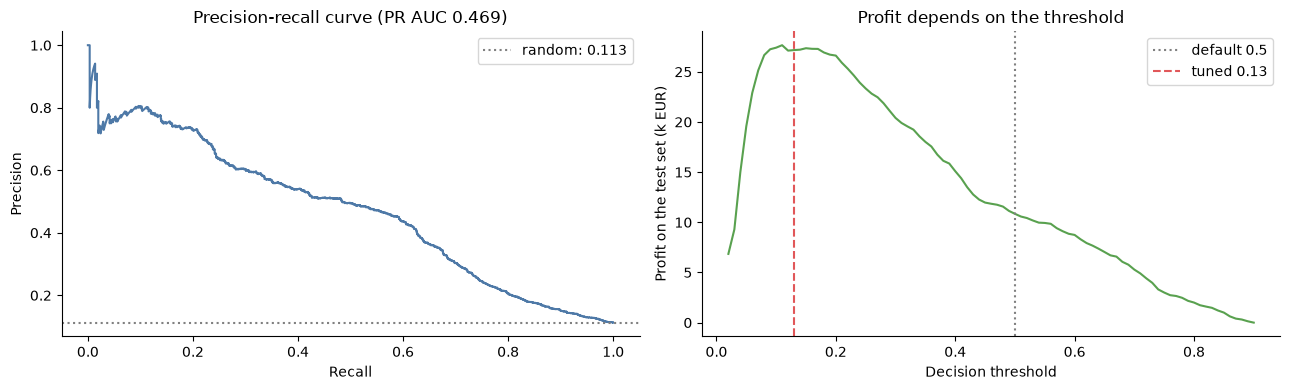

In [5]:
prec, rec, thr = precision_recall_curve(y_te, p)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(rec, prec, color="#4E79A7")
ax1.axhline(y_te.mean(), color="grey", ls=":", label=f"random: {y_te.mean():.3f}")
ax1.set(xlabel="Recall", ylabel="Precision", title=f"Precision-recall curve (PR AUC {average_precision_score(y_te, p):.3f})")
ax1.legend()
ax2.plot(thresholds, np.array(profits) / 1000, color="#59A14F")
ax2.axvline(0.5, color="grey", ls=":", label="default 0.5")
ax2.axvline(tuned.best_threshold_, color="#E15759", ls="--", label=f"tuned {tuned.best_threshold_:.2f}")
ax2.set(xlabel="Decision threshold", ylabel="Profit on the test set (k EUR)", title="Profit depends on the threshold")
ax2.legend()
plt.tight_layout()
plt.show()

The best threshold is far below 0.5 because a missed subscriber (50 € lost) costs ten times more than a wasted call (5 €). Threshold tuning uses the business costs directly and keeps the probabilities interpretable.

## 4. Summary

| Do | Avoid |
| :--- | :--- |
| evaluate with PR AUC, recall/precision, or a cost-based metric | accuracy on imbalanced data |
| tune the threshold for the real costs | the default 0.5 |
| use class weights or resampling inside the pipeline if the model needs it | resampling before the train/test split |
| keep the test set at the real class ratio | balancing the test set |
| recalibrate probabilities after resampling if you need probabilities (M16) | reading resampled probabilities as real risks |

*Insight: With imbalanced data, the ranking quality of a model and the decision rule are separate problems. Measure ranking with PR AUC, then choose the threshold from the real costs of errors; resampling is optional and must stay inside the training folds.*

## Real-World Use Case or Analogy

An imbalanced problem is like **airport security**: almost every bag is harmless, so "nothing is dangerous" is right 99.99 % of the time and still unacceptable. The security level (threshold) is set by the cost of missing a dangerous item compared with the cost of an extra check.

Fraud detection, medical screening, churn prevention and marketing campaigns all tune thresholds against business costs; the same model is often run with different thresholds for different customer segments.